# Model Evaluation and Comparison
Comparing every regression model built for predicting P. falciparum pEC50, on the same train/test split and the same 5 CV folds.

## 1. Setup and data

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# Load train/test split
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

y_train = train["pf_pEC50"]
y_test = test["pf_pEC50"]

print("Train:", train.shape)
print("Test:", test.shape)

Train: (1349, 14)
Test: (338, 14)


## 2. Features

In [29]:
# The 9 molecular descriptors
features = [
    "molecular_weight", "logp", "hba", "hbd", "psa",
    "rtb", "ro5_violations", "aromatic_rings", "heavy_atoms"
]

X_train_desc = train[features].to_numpy()
X_test_desc = test[features].to_numpy()

# Morgan fingerprints
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return generator.GetFingerprintAsNumPy(mol)

X_train_fp = np.array([smiles_to_fingerprint(s) for s in train["smiles"]])
X_test_fp = np.array([smiles_to_fingerprint(s) for s in test["smiles"]])

# Combined = fingerprints + descriptors (what RF, SVR and XGBoost used)
X_train_comb = np.hstack((X_train_fp, X_train_desc))
X_test_comb = np.hstack((X_test_fp, X_test_desc))

print("Descriptors:", X_train_desc.shape)
print("Combined:", X_train_comb.shape)

Descriptors: (1349, 9)
Combined: (1349, 1033)


## 3. Models and mean baseline

In [30]:
models = {
    "Mean baseline": (
        DummyRegressor(strategy="mean"),
        "descriptors"
    ),
    "Linear Regression": (
        make_pipeline(StandardScaler(), LinearRegression()),
        "descriptors"
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        "combined"
    ),
    "SVR": (
        make_pipeline(StandardScaler(),
                      SVR(kernel="rbf", C=1, epsilon=0.1, gamma=0.001)),
        "combined"
    ),
    "XGBoost": (
        XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8,
                     objective="reg:squarederror", random_state=42),
        "combined"
    ),
}

feature_sets = {
    "descriptors": (X_train_desc, X_test_desc),
    "combined": (X_train_comb, X_test_comb),
}

print("Models to compare:", list(models))

Models to compare: ['Mean baseline', 'Linear Regression', 'Random Forest', 'SVR', 'XGBoost']


## 4. Cross-validation and test scores

In [31]:
# Same 5 folds for every model, so the comparison is fair
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []

for name, (model, feature_set) in models.items():
    X_tr, X_te = feature_sets[feature_set]

    # 5-fold cross-validation on the TRAINING data only
    cv_results = cross_validate(
        model, X_tr, y_train, cv=cv,
        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"}
    )

    # Train on all the training data, then predict
    model.fit(X_tr, y_train)
    train_pred = model.predict(X_tr)
    test_pred = model.predict(X_te)

    rows.append({
        "Model": name,
        "Features": feature_set,
        "Train R2": r2_score(y_train, train_pred),
        "CV R2": cv_results["test_r2"].mean(),
        "CV R2 std": cv_results["test_r2"].std(),
        "Test R2": r2_score(y_test, test_pred),
        "CV RMSE": -cv_results["test_rmse"].mean(),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
    })

    print(name, "done")

results = pd.DataFrame(rows).round(3)
results

Mean baseline done
Linear Regression done
Random Forest done
SVR done
XGBoost done


,Model,Features,Train R2,CV R2,CV R2 std,Test R2,CV RMSE,Test RMSE
0,Mean baseline,descriptors,0.000,-0.006,0.008,-0.002,0.553,0.584
1,Linear Regression,descriptors,0.046,0.022,0.032,0.044,0.545,0.570
2,Random Forest,combined,0.875,0.142,0.031,0.148,0.510,0.538
3,SVR,combined,0.820,0.146,0.062,0.121,0.508,0.547
4,XGBoost,combined,0.554,0.112,0.044,0.120,0.519,0.547


## 5. Model comparison chart

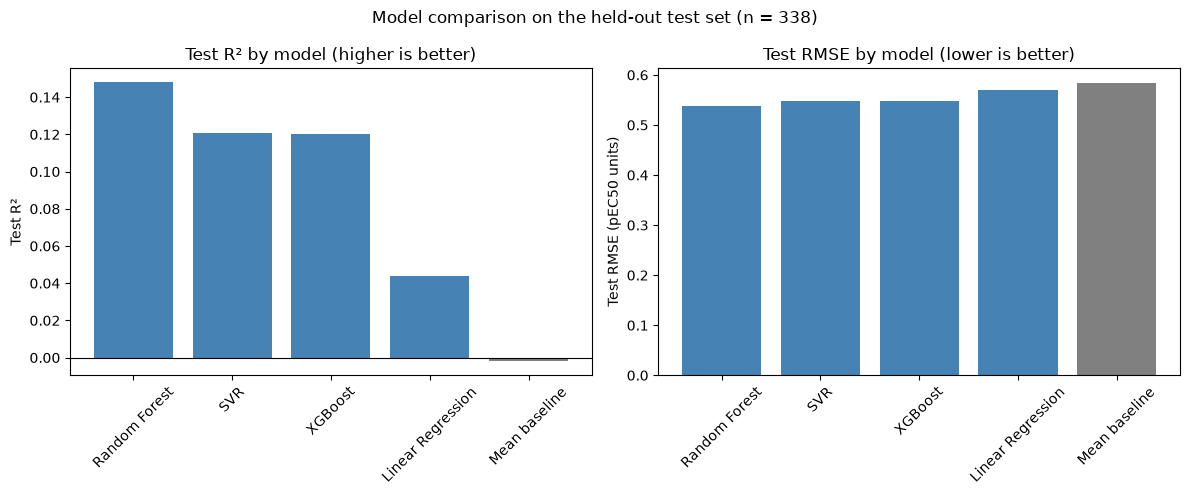

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

order = results.sort_values("Test R2", ascending=False)
colours = ["grey" if m == "Mean baseline" else "steelblue"
           for m in order["Model"]]

# Left: test R2
axes[0].bar(order["Model"], order["Test R2"], color=colours)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Test R²")
axes[0].set_title("Test R² by model (higher is better)")
axes[0].tick_params(axis="x", rotation=45)

# Right: test RMSE
axes[1].bar(order["Model"], order["Test RMSE"], color=colours)
axes[1].set_ylabel("Test RMSE (pEC50 units)")
axes[1].set_title("Test RMSE by model (lower is better)")
axes[1].tick_params(axis="x", rotation=45)

fig.suptitle("Model comparison on the held-out test set (n = 338)")
fig.tight_layout()
fig.savefig("../results/figures/model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Overfitting check: train vs CV vs test

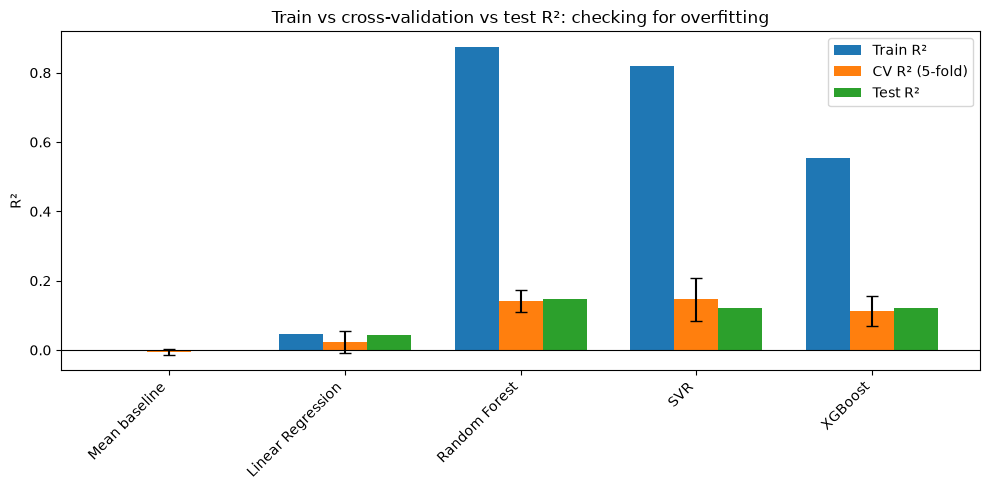

In [33]:
x = np.arange(len(results))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x - width, results["Train R2"], width, label="Train R²")
ax.bar(x, results["CV R2"], width,
       yerr=results["CV R2 std"], capsize=4, label="CV R² (5-fold)")
ax.bar(x + width, results["Test R2"], width, label="Test R²")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(results["Model"], rotation=45, ha="right")
ax.set_ylabel("R²")
ax.set_title("Train vs cross-validation vs test R²: checking for overfitting")
ax.legend()

fig.tight_layout()
plt.show()

## 7. Classification model summary

The team also tested the problem as a classification task, splitting compounds
into potent (pEC50 ≥ 6) and less potent (pEC50 < 6). The test set contains
146 potent and 192 less potent compounds, so always guessing "less potent"
would already score 57% accuracy.

| Random Forest classifier | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Default threshold (0.50) | 0.663 | 0.663 | 0.445 | 0.533 |
| Tuned threshold (0.40) | 0.651 | 0.576 | 0.726 | 0.642 |

Lowering the threshold to 0.40, chosen by cross-validation on the training
set, trades a little accuracy for much better recall: the model now finds
73% of the genuinely potent compounds instead of 45%. For drug discovery
that is the right trade, since missing an active compound costs more than
testing an inactive one.

Classification results reproduced from `classification.ipynb`.


## 8. Discussion and limitations

### What the comparison shows

Every model did better than just guessing the average, but not by a lot.
The best one was Random Forest, with a test R² of 0.148. That means it
explains about 15% of why some compounds are more potent than others, and
leaves 85% unexplained. Its typical error was 0.54 pEC50 units, barely
better than the baseline's 0.58. An error that size means the real potency
could be about three times stronger or weaker than predicted. So these
models are useful for putting compounds in a rough order to test first,
but they cannot replace a lab experiment.

Linear regression scored 0.044, which is almost the same as guessing. This
tells us the link between the nine molecular properties and potency is not
a straight line. Adding the Morgan fingerprints, which describe the actual
structure of the molecule, roughly tripled the score. So structure matters
more than overall properties like size and greasiness.

### Overfitting

Random Forest and SVR both scored very high on the data they were trained
on (R² 0.875 and 0.820) but much lower on data they had not seen (about
0.14). This means they are memorising the training compounds instead of
learning rules that work on new ones.

Cross-validation and test scores came out close for every model. That is a
good sign: it means the 80/20 split was fair, and no one got a high score
just by luck.

### Limitations

Random Forest, SVR and XGBoost scored 0.148, 0.121 and 0.120. Those gaps
are smaller than the amount each model's score moved between folds, so we
cannot say any one of them is really the best.

Part of the problem is the data itself. The 1,687 compounds come from many
different chemical families, and their EC50 values were measured in
different labs using different methods. Some of the variation is just
measurement noise, and no model can predict noise.